<a href="https://colab.research.google.com/github/lakshanya-j/Projects/blob/main/AprioriAlgorithmOnGroceryStoreDataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 5 Transactions:
[['MILK', 'BREAD', 'BISCUIT'], ['BREAD', 'MILK', 'BISCUIT', 'CORNFLAKES'], ['BREAD', 'TEA', 'BOURNVITA'], ['JAM', 'MAGGI', 'BREAD', 'MILK'], ['MAGGI', 'TEA', 'BISCUIT']]

Dataset Shape: (20, 11)

Missing Values: 0

Support for Single Items:
BREAD         0.65
COFFEE        0.40
BISCUIT       0.35
TEA           0.35
SUGER         0.30
CORNFLAKES    0.30
MILK          0.25
MAGGI         0.25
BOURNVITA     0.20
COCK          0.15
JAM           0.10
dtype: float64

Support for Pairs:
BISCUIT     BREAD         0.20
MAGGI       TEA           0.20
COFFEE      SUGER         0.20
            CORNFLAKES    0.20
BREAD       TEA           0.20
            SUGER         0.20
            MILK          0.20
            MAGGI         0.15
COCK        COFFEE        0.15
BISCUIT     CORNFLAKES    0.15
BOURNVITA   BREAD         0.15
BREAD       COFFEE        0.15
CORNFLAKES  MILK          0.10
JAM         MAGGI         0.10
CORNFLAKES  TEA           0.10
BOURNVITA   SUGER         0.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


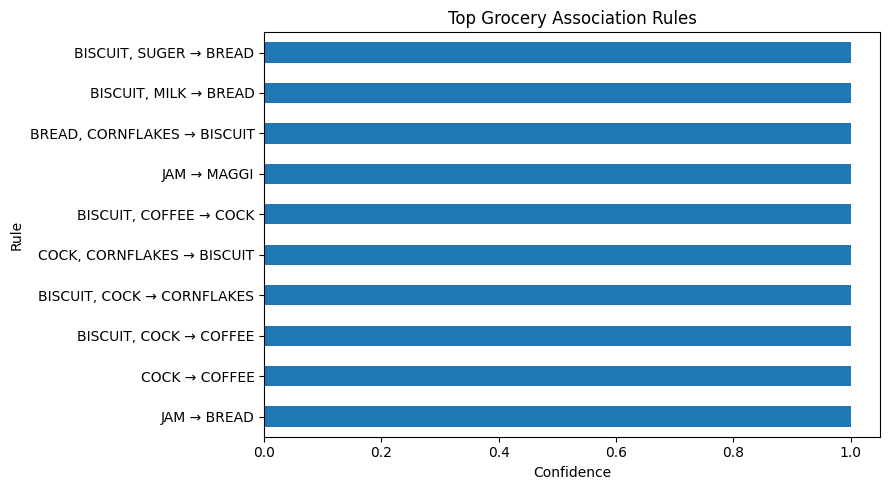


Conclusion:
The Apriori algorithm identifies frequently purchased grocery items and association rules. Support measures how often items occur together, confidence measures the likelihood of purchasing one item when another is purchased, and lift measures the strength of their association.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from mlxtend.frequent_patterns import apriori, association_rules

df = pd.read_csv("GroceryStoreDataSet.csv", header=None)

transactions = df[0].dropna().apply(
    lambda x: [item.strip() for item in x.split(",")]
).tolist()

items = sorted(set(item for transaction in transactions for item in transaction))

tidy_data = pd.DataFrame([
    {item: item in transaction for item in items}
    for transaction in transactions
])

print("First 5 Transactions:")
print(transactions[:5])

print("\nDataset Shape:", tidy_data.shape)
print("\nMissing Values:", tidy_data.isnull().sum().sum())

single_support = tidy_data.mean().sort_values(ascending=False)

print("\nSupport for Single Items:")
print(single_support)

pair_support = {}

for pair in combinations(items, 2):
    pair_support[pair] = sum(
        pair[0] in t and pair[1] in t for t in transactions
    ) / len(transactions)

print("\nSupport for Pairs:")
print(pd.Series(pair_support).sort_values(ascending=False))

frequent_itemsets = apriori(
    tidy_data,
    min_support=0.05,
    use_colnames=True
)

print("\nFrequent Itemsets:")
print(frequent_itemsets)

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.3
)

print("\nAssociation Rules:")
print(rules[["antecedents", "consequents", "support", "confidence", "lift"]])

if not rules.empty:
    rules["Rule"] = rules.apply(
        lambda row: ", ".join(row["antecedents"]) + " → " +
        ", ".join(row["consequents"]),
        axis=1
    )

    rules.sort_values("confidence", ascending=False).head(10).plot(
        x="Rule", y="confidence", kind="barh", figsize=(9, 5),
        legend=False
    )
    plt.title("Top Grocery Association Rules")
    plt.xlabel("Confidence")
    plt.tight_layout()
    plt.show()

print("\nConclusion:")
print("The Apriori algorithm identifies frequently purchased grocery items and association rules. Support measures how often items occur together, confidence measures the likelihood of purchasing one item when another is purchased, and lift measures the strength of their association.")